# Regional forecast pilot: review before publishing
The experimental probability of at least one new fire episode
**detected** in a department during one week is estimated. It is not the percentage of
territory burned, severity or verified physical ignition. Each week is
independent as a query: lead time 12 does not mean cumulative risk.

In [1]:
from pathlib import Path
import hashlib,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

repo=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'data/regional_outlook.json').exists())
raw=(repo/'data/regional_outlook.json').read_bytes()
document=json.loads(raw);meta=document['metadata']
manifest=json.loads((repo/'data/regional_outlook_manifest.json').read_text(encoding='utf-8'))
assert hashlib.sha256(raw).hexdigest()==manifest['sha256']
data=pd.DataFrame(document['data'])
folder=repo/'reports/prediction/pilot'
figures=folder/'figures';figures.mkdir(parents=True,exist_ok=True)
print('Emisión real:',meta['issued_at'])
print('Corte semanal de referencia:',meta['feature_reference_at'])
print('Primera y última semana:',data.target_week_start.min(),data.target_week_start.max())
print('Fin exclusivo del último objetivo:',data.target_week_end_exclusive.max())

Emisión real: 2026-11-15T20:39:33.425766+00:00
Corte semanal de referencia: 2026-11-15T00:00:00-05:00
Primera y última semana: 2026-11-16 2027-02-01
Fin exclusivo del último objetivo: 2027-02-08


## 1. Are the 300 combinations complete?
25 departments by 12 weeks. The values are regional probabilities,
not the sum of cell probabilities. Missing values must stay null
with an explicit reason; here the inputs allow computing all 300 outputs.

In [2]:
assert len(data)==300 and not data.duplicated(['region_id','lead_weeks']).any()
assert set(data.lead_weeks)==set(range(1,13)) and data.region_id.nunique()==25
assert data.probability.between(0,1).all()
assert np.allclose(data.probability*100,data.probability_percent,atol=1e-9,rtol=0)
display(data.groupby(['estimation_status','quality_status']).size().rename('filas').to_frame())
first=data.loc[data.lead_weeks.eq(1)].sort_values('region_name')
display(first[['region_id','region_name','target_week_start','probability_percent']].round(2))

,,filas
estimation_status,quality_status,
estimated,experimental,300


,region_id,region_name,target_week_start,probability_percent
0,01,AMAZONAS,2026-11-16,96.50
12,02,ANCASH,2026-11-16,98.07
24,03,APURIMAC,2026-11-16,89.02
36,04,AREQUIPA,2026-11-16,97.75
48,05,AYACUCHO,2026-11-16,94.01
60,06,CAJAMARCA,2026-11-16,98.72
72,07,CALLAO,2026-11-16,11.07
84,08,CUSCO,2026-11-16,97.67
96,09,HUANCAVELICA,2026-11-16,87.19
108,10,HUANUCO,2026-11-16,97.84


## 2. All weeks and departments
A large region can have a high percentage because a single episode
anywhere in the region is enough. The historical positive prevalence was high
(about 84 % in training); do not read these percentages as
certainty of a destructive fire. The model may also pick up agricultural burning.

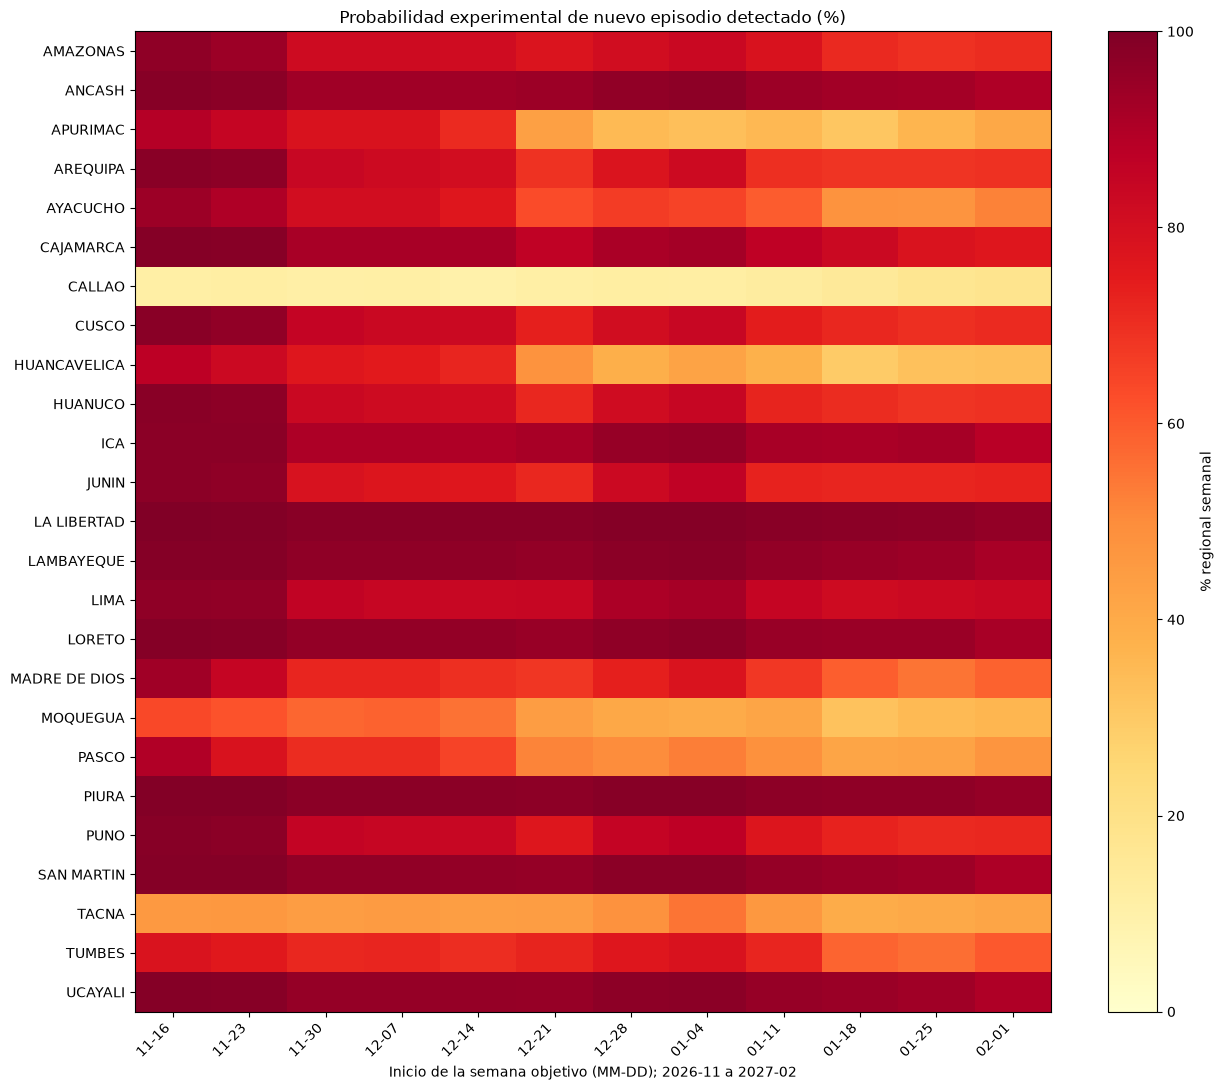

In [3]:
matrix=data.pivot(index='region_name',columns='target_week_start',values='probability_percent').sort_index()
fig,ax=plt.subplots(figsize=(13,11))
image=ax.imshow(matrix.to_numpy(),vmin=0,vmax=100,cmap='YlOrRd',aspect='auto')
ax.set_xticks(range(12),[x[5:] for x in matrix.columns],rotation=45,ha='right')
ax.set_yticks(range(25),matrix.index)
ax.set_xlabel('Inicio de la semana objetivo (MM-DD); 2026-11 a 2027-02')
ax.set_title('Probabilidad experimental de nuevo episodio detectado (%)')
fig.colorbar(image,ax=ax,label='% regional semanal')
fig.tight_layout();fig.savefig(figures/'regional_outlook_heatmap.png',dpi=150);plt.show()

## 3. Comparison with climatology and signals outside the historical range
Climatology is a reference, not the truth. The model improves on
it in 2025 and 2026, but ties in 2024. Calibration did not improve the joint
test. No other variant was selected after seeing those results.
The range warnings compare features with the 2018–2021 training;
they are not confidence intervals and do not correct the percentage automatically.

,region_name,probability_percent,climatology_percent,outside_training_range_count
0,AMAZONAS,96.50,88.18,7
12,ANCASH,98.07,92.42,8
24,APURIMAC,89.02,85.48,4
36,AREQUIPA,97.75,95.48,4
48,AYACUCHO,94.01,85.35,6
60,CAJAMARCA,98.72,95.76,9
72,CALLAO,11.07,4.95,2
84,CUSCO,97.67,94.65,5
96,HUANCAVELICA,87.19,74.74,5
108,HUANUCO,97.84,95.20,4


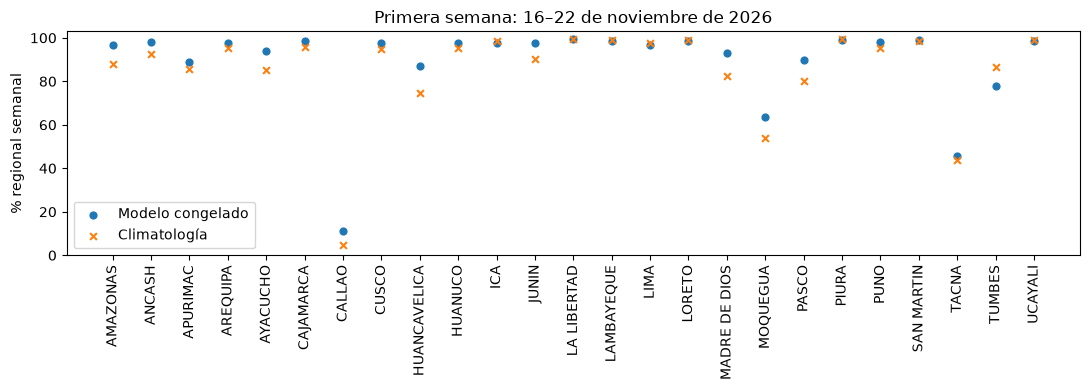

In [4]:
review=first[['region_name','probability_percent','climatology_probability_for_review',
    'features_outside_region_training_range']].copy()
review['climatology_percent']=100*review.pop('climatology_probability_for_review')
review['outside_training_range_count']=review.features_outside_region_training_range.map(len)
display(review.drop(columns='features_outside_region_training_range').round(2))
fig,ax=plt.subplots(figsize=(11,4))
ax.scatter(first.region_name,first.probability_percent,label='Modelo congelado',s=24)
ax.scatter(first.region_name,first.climatology_probability_for_review*100,label='Climatología',s=24,marker='x')
ax.set_ylim(0,103);ax.set_ylabel('% regional semanal');ax.tick_params(axis='x',rotation=90)
ax.legend();ax.set_title('Primera semana: 16–22 de noviembre de 2026')
fig.tight_layout();fig.savefig(figures/'first_week_vs_climatology.png',dpi=150);plt.show()

## 4. Validity, provenance and limits of this delivery
No realized future weather was used and no daily forecast 12 weeks ahead
was invented. The signal is mainly region and season. POWER is
one point per department, not an average over the whole territory. The historical
availability of weather data was simulated with latency; vintages were not reconstructed.
NRT has no confirmed type and its transfer from SP has not been validated yet
with future results. This first issue has no automatic refresh.
It expires on Sunday 22 November at 00:00 Lima time: then the API refuses
percentages until there is a renewed issue. It does not retrain per request.

In [5]:
display(pd.Series({k:meta[k] for k in ['NRT_last_acquisition_utc','NRT_ingested_at',
    'reference_cutoff_exclusive','weather_value_days_used','weather_last_source_day',
    'NRT_SP_transfer_validated','NRT_type0_assumed','automatic_refresh_configured',
    'physical_ignition_probability_verified','calibration_improvement_demonstrated']},name='valor').to_frame())
for name in ['pilot_verification.json','feature_parity_report.json','local_api_review.json','docker_HTTP_verification.json','public_HTTP_verification.json']:
    evidence=json.loads((folder/name).read_text(encoding='utf-8'))
    print(name);display(evidence)

,valor
NRT_last_acquisition_utc,2026-11-13T18:47:00+00:00
NRT_ingested_at,2026-11-15T19:57:24.154479+00:00
reference_cutoff_exclusive,2026-11-12T05:00:00+00:00
weather_value_days_used,[2026-11-07]
weather_last_source_day,2026-11-12
NRT_SP_transfer_validated,False
NRT_type0_assumed,False
automatic_refresh_configured,False
physical_ignition_probability_verified,False
calibration_improvement_demonstrated,False


pilot_verification.json


{'status': 'forecast_grid_generated_for_review',
 'rows': 300,
 'regions': 25,
 'leads': 12,
 'unique_region_lead_keys': 300,
 'json_sha256': 'a36fc84eaeb60e1528822d59b6c345e39ba628c0dbb2817e8b48b3e257a0b513',
 'model_hash_unchanged': True,
 'model_retrained': False,
 'feature_parity_rows': 115350,
 'future_suffix_does_not_change_NRT_past': True,
 'issue_time_is_actual_generation_time': True,
 'estimated_rows': 300,
 'unavailable_rows': 0,
 'physical_ignition_probability_verified': False,
 'public_api_modified': False}

feature_parity_report.json


{'status': 'all_frozen_training_features_match',
 'rows_checked': 115350,
 'absolute_tolerance': 1e-12,
 'rtol': 0,
 'missingness_matches': True,
 'max_absolute_difference_by_feature': {'target_season_sin': 1.1102230246251565e-16,
  'target_season_cos': 1.1102230246251565e-16,
  'center_lon': 0.0,
  'center_lat': 1.7763568394002505e-15,
  'log_harmonized_annual_context': 8.881784197001252e-16,
  'harmonized_annual_context_missing': 0.0,
  'harmonized_context_instruments': 0.0,
  'log_ref_records_7d': 8.881784197001252e-16,
  'log_ref_frp_sum_7d': 1.7763568394002505e-15,
  'log_detected_onsets_7d': 8.881784197001252e-16,
  'log_ref_records_28d': 1.7763568394002505e-15,
  'log_ref_frp_sum_28d': 1.7763568394002505e-15,
  'log_detected_onsets_28d': 8.881784197001252e-16,
  'log_ref_records_90d': 1.7763568394002505e-15,
  'log_ref_frp_sum_90d': 1.7763568394002505e-15,
  'log_detected_onsets_90d': 1.7763568394002505e-15,
  'days_since_ref_record': 2.842170943040401e-14,
  'ref_no_records_90d

local_api_review.json


{'stage': 'local_only_pending_release_review',
 'API_version': '0.4.0',
 'HTTP_status': 200,
 'cors_passed': True,
 'API_tests_passed': 43,
 'inference_tests_passed': 5,
 'public_api_modified': False,
 'snapshot_id': '298c81cf5373e5cef02882a81f5525a14b383d94cfcb9340a1a323be36f61e19',
 'causal_label_tests_passed': 3,
 'model_tests_passed': 2,
 'total_distinct_unit_tests_passed': 53,
 'Docker_build_passed': True,
 'Docker_nonroot_checks_passed': True,
 'HTTP_checks_passed': 11,
 'local_review_url': 'http://127.0.0.1:8010/docs'}

docker_HTTP_verification.json


{'status': 'verified',
 'base_url': 'http://127.0.0.1:8010',
 'checks': ['snapshot',
  'cors',
  'regions',
  'point_location',
  'regional_series_values',
  'forecast',
  'no_public_index_rebuild',
  'risk_metadata',
  'risk_grid_300',
  'risk_region_week',
  'risk_cors'],
 'events_integration': 'not_included_in_this_service',
 'risk_snapshot_id': '298c81cf5373e5cef02882a81f5525a14b383d94cfcb9340a1a323be36f61e19'}

public_HTTP_verification.json


{'status': 'verified',
 'base_url': 'https://modis-viirs-harmonization-production.up.railway.app',
 'checks': ['snapshot',
  'cors',
  'regions',
  'point_location',
  'regional_series_values',
  'forecast',
  'no_public_index_rebuild',
  'risk_metadata',
  'risk_grid_300',
  'risk_region_week',
  'risk_cors'],
 'events_integration': 'not_included_in_this_service',
 'risk_snapshot_id': '298c81cf5373e5cef02882a81f5525a14b383d94cfcb9340a1a323be36f61e19',
 'verified_at': '2026-11-15T21:16:45.067698+00:00',
 'code_commit': '375aa69d8176b34cf85ef28f7f786f04c7440153',
 'public_api_modified': True}

## 5. Query by region and week
Endpoint approved, published and verified on Railway:
`/v1/fire-risk?region_id=08&target_week_start=2026-11-16`.
The response keeps the version, issue/target dates, input quality
and percentage. The region selection on the website can use `/v1/regions`.
A percentage of 97.7 % in Cusco means at least one new episode detected
anywhere in the region during that week; not that 97.7 % of Cusco will burn.

In [6]:
example=json.loads((folder/'example_response_cusco.json').read_text(encoding='utf-8'))
display(example['data'])
print('Estado del objetivo:',example['metadata']['target_period_status'])
print('Vigente hasta:',example['metadata']['valid_until'])
print('Interpretación:',example['metadata']['interpretation_es'])
print('Publicación experimental aprobada; evidencia HTTP pública en reports/prediction/pilot/public_HTTP_verification.json.')

[{'region_id': '08',
  'region_name': 'CUSCO',
  'issued_at': '2026-11-15T20:39:33.425766Z',
  'target_week_start': '2026-11-16',
  'target_week_end_exclusive': '2026-11-23',
  'lead_weeks': 1,
  'probability': 0.9766537735489415,
  'probability_percent': 97.66537735489415,
  'estimation_status': 'estimated',
  'quality_status': 'experimental',
  'unavailable_reasons': [],
  'features_outside_region_training_range': ['days_since_ref_record',
   't2m_mean_7d',
   't2m_mean_28d',
   'ws2m_mean_28d',
   't2m_mean_90d']}]

Estado del objetivo: upcoming
Vigente hasta: 2026-11-22T00:00:00-05:00
Interpretación: Probabilidad experimental de al menos un nuevo episodio detectado en la región durante esa semana; no ignición física verificada.
Publicación experimental aprobada; evidencia HTTP pública en reports/prediction/pilot/public_HTTP_verification.json.
